In [148]:
from google.colab import drive

drive.mount('/content/drive')

FOLDERNAME = 'computer vision project'
assert FOLDERNAME is not None, "[!] Enter the foldername."
FullPath = '/content/drive/MyDrive/' + FOLDERNAME
print(FullPath)

import os
os.chdir(FullPath)
!pwd # check that your folder is the current working directory

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append(FullPath)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/computer vision project
/content/drive/.shortcut-targets-by-id/1sbXfmKBOtc8W59mIn-zpOg2Eoc8bG4bO/computer vision project


In [149]:
import pandas as pd
import numpy as np
import cv2 as cv
from PIL import Image
from pathlib import Path

import preprocessing as prep

# Matplotlib is a useful plotting library for python
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
# This code is to make matplotlib figures appear inline in the
# notebook rather than in a new window.
%matplotlib inline

In [150]:
# Define filepaths
dataset_path = Path(FullPath+'/db_lisa_tiny')
annotations_filepath = dataset_path / 'annotations.csv'

# Create dataframe for annotations
df_annotations = pd.read_csv(annotations_filepath)

# Define sample image
img_num = 595 # 1 - 900 #540
img_original = cv.imread(dataset_path / f"sample_{img_num:03}.png", cv.IMREAD_COLOR_RGB)

# Define bounding boxes per test image
row_mask = df_annotations["filename"] == f"sample_{img_num:03}.png"
annotation = df_annotations.loc[row_mask]
display(annotation)

x1 = int(annotation.iloc[0]["x1"])
y1 = int(annotation.iloc[0]["y1"])
x2 = int(annotation.iloc[0]["x2"])
y2 = int(annotation.iloc[0]["y2"])

,filename,x1,y1,x2,y2,class
594,sample_595.png,428,31,465,63,pedestrianCrossing


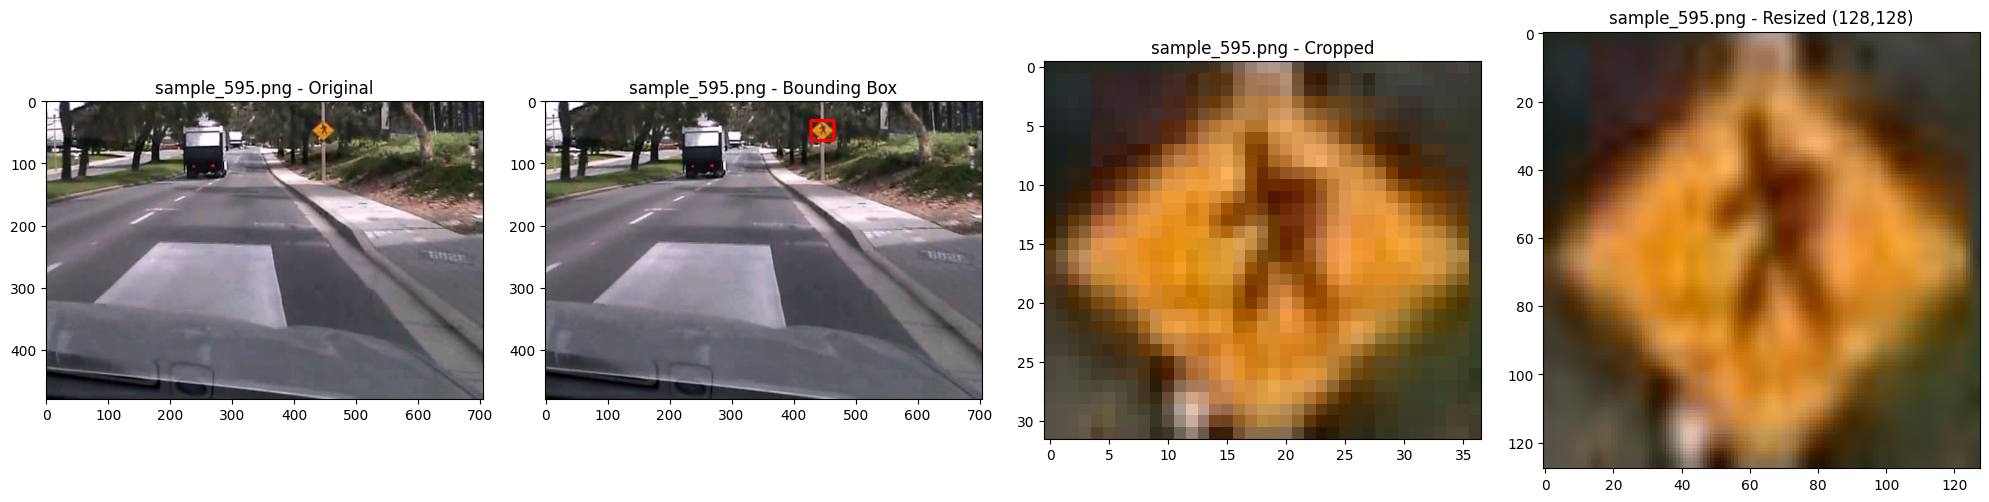

In [151]:
# ------------------------------------------------------
# TEST: Bounding boxes
# ------------------------------------------------------
fig, ax = plt.subplots(1,4, figsize=(20,8))

# Original image (img)
ax[0].set_title(f"sample_{img_num:03}.png - Original")
ax[0].imshow(img_original)

# Original image with bounding box drawn on
img_box = prep.draw_bounding_box(img_original, x1, y1, x2, y2)
ax[1].set_title(f"sample_{img_num:03}.png - Bounding Box")
ax[1].imshow(img_box)

# Crop image to bounding box
img_cropped = prep.crop_img_to_bounds(img_original, x1, y1, x2, y2)
ax[2].set_title(f"sample_{img_num:03}.png - Cropped")
ax[2].imshow(img_cropped)

# Resize
size = 128
img = cv.resize(img_cropped.copy(), (size,size), interpolation = cv.INTER_CUBIC) # uses bicubic interpolation
ax[3].set_title(f"sample_{img_num:03}.png - Resized ({size},{size})")
ax[3].imshow(img)

plt.tight_layout()
plt.show()

(np.float64(-0.5), np.float64(703.5), np.float64(479.5), np.float64(-0.5))

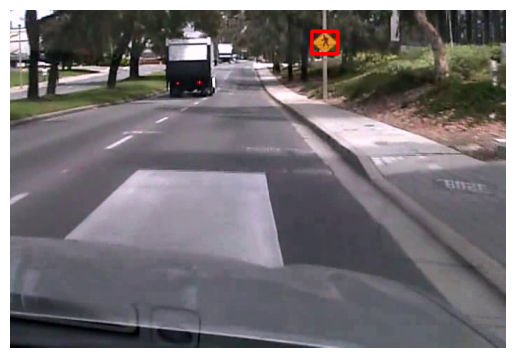

In [152]:
# Original image with bounding box drawn on
img_box = prep.draw_bounding_box(img_original, x1, y1, x2, y2)
plt.imshow(img_box)
plt.axis('off')

(np.float64(-0.5), np.float64(36.5), np.float64(31.5), np.float64(-0.5))

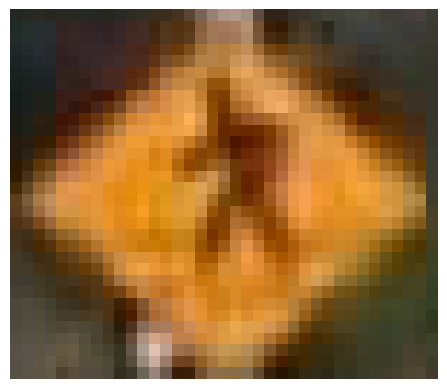

In [153]:
# Crop image to bounding box
img_cropped = prep.crop_img_to_bounds(img_original, x1, y1, x2, y2)
plt.imshow(img_cropped)
plt.axis('off')

In [154]:
'''
sign_ids = [9, 211, 256, 304, 402, 503, 601, 715, 827]
labels_list = [
    "Stop", "Yield", "Yield Ahead",
    "Merge", "Signal Ahead", "Pedestrian Crossing",
    "Keep Right", "Speed Limit 35", "Speed Limit 25"
]

all_signs = {}

for img_num in sign_ids:
  filename = f"sample_{img_num:03}.png"
  img = cv.imread(dataset_path / f"sample_{img_num:03}.png", cv.IMREAD_COLOR_RGB)

  all_signs[img_num] = img


def crop_sign(img_num, image, df_annotations):
  filename = f"sample_{img_num:03}.png"

  row_mask = df_annotations["filename"] == f"sample_{img_num:03}.png"
  annotation = df_annotations.loc[row_mask]

  x1 = int(annotation.iloc[0]["x1"])
  y1 = int(annotation.iloc[0]["y1"])
  x2 = int(annotation.iloc[0]["x2"])
  y2 = int(annotation.iloc[0]["y2"])

  cropped = image[y1:y2, x1:x2]  # IMPORTANT: (row, col) = (y, x)

  return cropped

cropped_signs = {}

for img_num, img in all_signs.items():
  cropped_signs[img_num] = crop_sign(img_num, img, df_annotations)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, ((key, img), label) in zip(axes.flatten(), zip(cropped_signs.items(), labels_list)):
    ax.imshow(img)
    ax.set_title(label)
    ax.axis('off')

plt.tight_layout()
plt.show()
'''

'\nsign_ids = [9, 211, 256, 304, 402, 503, 601, 715, 827]\nlabels_list = [\n    "Stop", "Yield", "Yield Ahead",\n    "Merge", "Signal Ahead", "Pedestrian Crossing",\n    "Keep Right", "Speed Limit 35", "Speed Limit 25"\n]\n\nall_signs = {}\n\nfor img_num in sign_ids:\n  filename = f"sample_{img_num:03}.png"\n  img = cv.imread(dataset_path / f"sample_{img_num:03}.png", cv.IMREAD_COLOR_RGB)\n  \n  all_signs[img_num] = img\n\n\ndef crop_sign(img_num, image, df_annotations):\n  filename = f"sample_{img_num:03}.png"\n\n  row_mask = df_annotations["filename"] == f"sample_{img_num:03}.png"\n  annotation = df_annotations.loc[row_mask]\n    \n  x1 = int(annotation.iloc[0]["x1"])\n  y1 = int(annotation.iloc[0]["y1"])\n  x2 = int(annotation.iloc[0]["x2"])\n  y2 = int(annotation.iloc[0]["y2"])\n    \n  cropped = image[y1:y2, x1:x2]  # IMPORTANT: (row, col) = (y, x)\n    \n  return cropped\n\ncropped_signs = {}\n\nfor img_num, img in all_signs.items():\n  cropped_signs[img_num] = crop_sign(img_num,

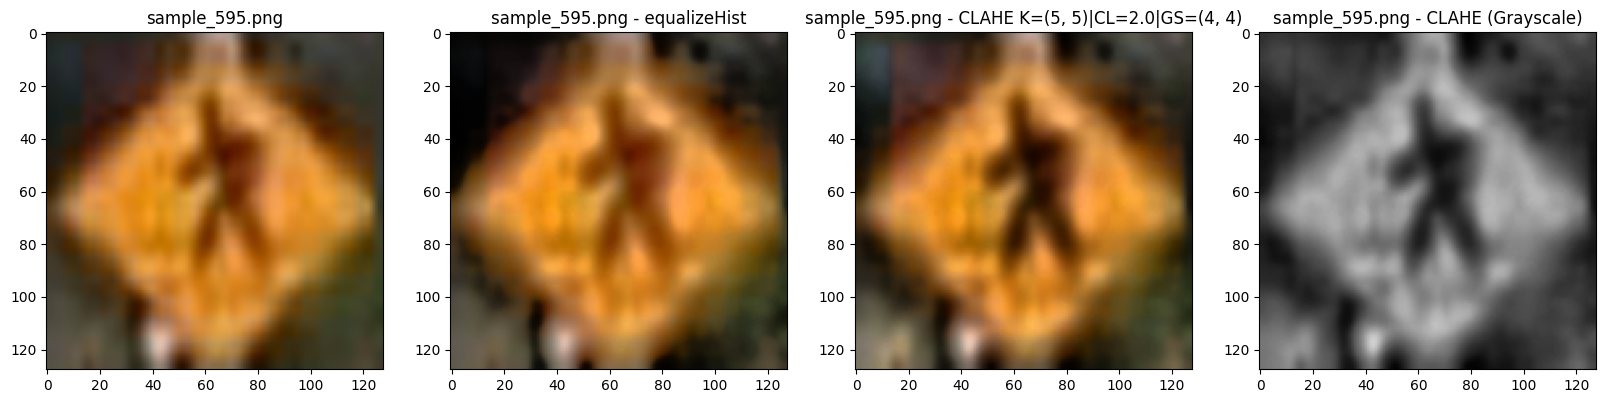

In [155]:
# ------------------------------------------------------
# TEST: Contrast enhancement via histogram equalization and CLAHE
# ------------------------------------------------------

# ------------------------------------------------------
# CLAHE Settings
kernel = (5,5)
cliplimit = 2.0
gridsize = (4,4)
# ------------------------------------------------------

# HSV CLAHE
img_hsv_clahe = prep.hsv_clahe(img, ksize=kernel, clipLimit=cliplimit, tileGridSize=gridsize)

# Convert RGB to Gray
img_hsv2gray_clahe = cv.cvtColor(img_hsv_clahe, cv.COLOR_RGB2GRAY)

# Histogram equalization
img_hist_eq = prep.hsv_hist_eq(img)

fig, ax = plt.subplots(1,4, figsize=(20,8))

# Original image (img)
ax[0].set_title(f"sample_{img_num:03}.png")
ax[0].imshow(img)

# Histogram equalization
ax[1].set_title(f"sample_{img_num:03}.png - equalizeHist")
ax[1].imshow(img_hist_eq)

# HSV CLAHE
ax[2].set_title(f"sample_{img_num:03}.png - CLAHE K={kernel}|CL={cliplimit}|GS={gridsize}")
ax[2].imshow(img_hsv_clahe)

# HSV CLAHE
ax[3].set_title(f"sample_{img_num:03}.png - CLAHE (Grayscale)")
ax[3].imshow(img_hsv2gray_clahe, cmap='gray', vmin=0, vmax=255)


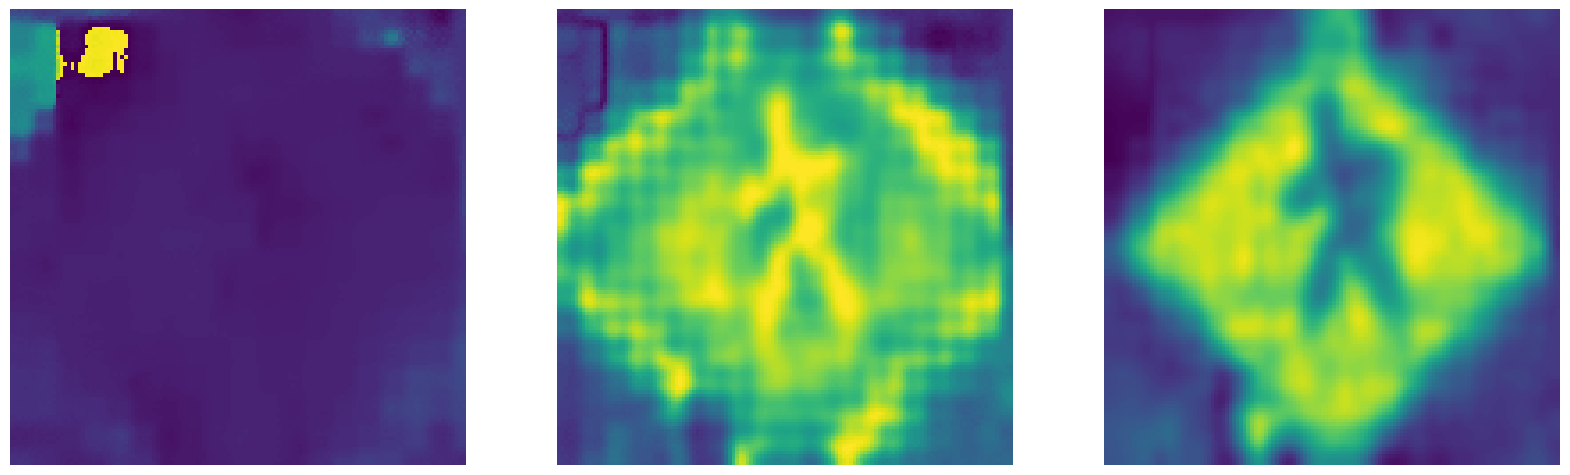

In [171]:
# Blur image to reduce noise
img_blurred = cv.GaussianBlur(img, (5,5), 0)

# Convert image to HSV
img_hsv = cv.cvtColor(img_blurred, cv.COLOR_RGB2HSV)
h, s, v = cv.split(img_hsv)

fig, ax = plt.subplots(1,3, figsize=(20,8))
ax[0].axis('off')
ax[1].axis('off')
ax[2].axis('off')
ax[0].imshow(h)
ax[1].imshow(s)
ax[2].imshow(v)


(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

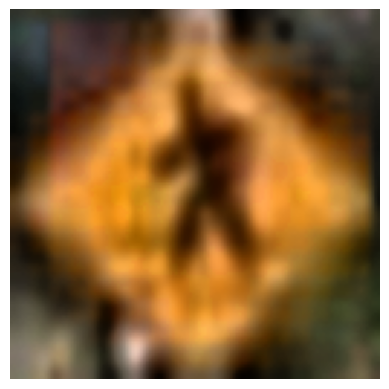

In [157]:
# HSV CLAHE
plt.imshow(img_hsv_clahe)
plt.axis('off')

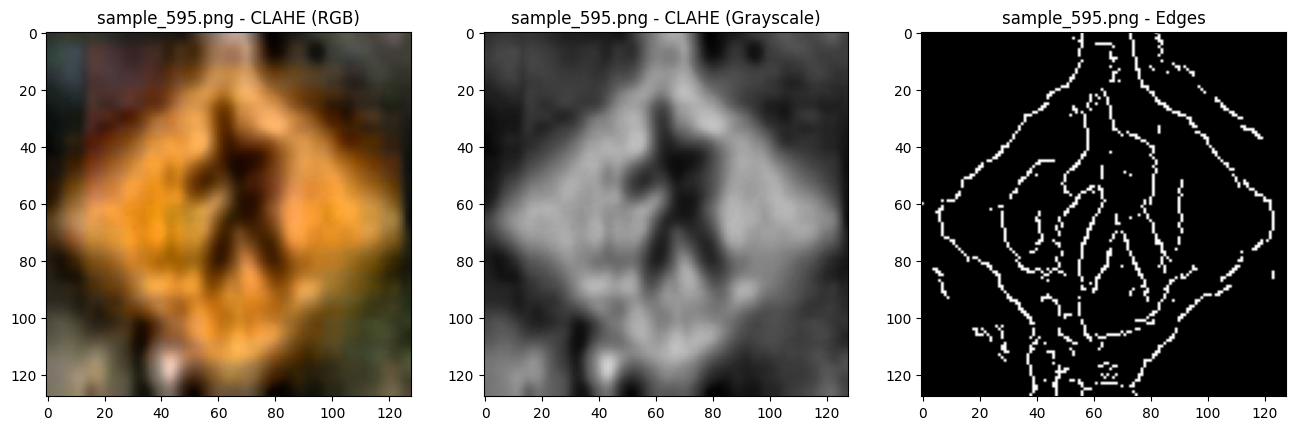

In [158]:
# ------------------------------------------------------
# TEST: Edge detection
# ------------------------------------------------------

# ------------------------------------------------------
# Canny Edge Settings
kernel = (15,15)
low_scale = 0.1
upper_scale = 0.6
# ------------------------------------------------------

edges = prep.canny_edge(img, ksize=kernel, low_scale=low_scale, upper_scale=upper_scale)

fig, ax = plt.subplots(1,3, figsize=(16,8))

# HSV CLAHE (RGB)
ax[0].set_title(f"sample_{img_num:03}.png - CLAHE (RGB)")
ax[0].imshow(img_hsv_clahe)

# HSV CLAHE (Grayscale)
ax[1].set_title(f"sample_{img_num:03}.png - CLAHE (Grayscale)")
ax[1].imshow(img_hsv2gray_clahe, cmap='gray', vmin=0, vmax=255)

# HSV Edge
ax[2].set_title(f"sample_{img_num:03}.png - Edges")
ax[2].imshow(edges, cmap='gray', vmin=0, vmax=255)


(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

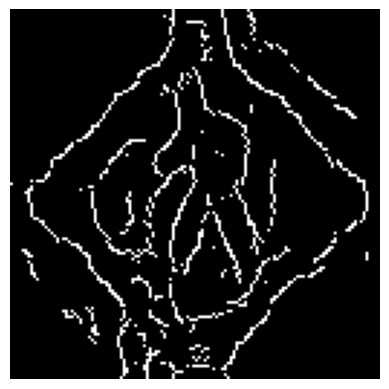

In [164]:
plt.imshow(edges, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

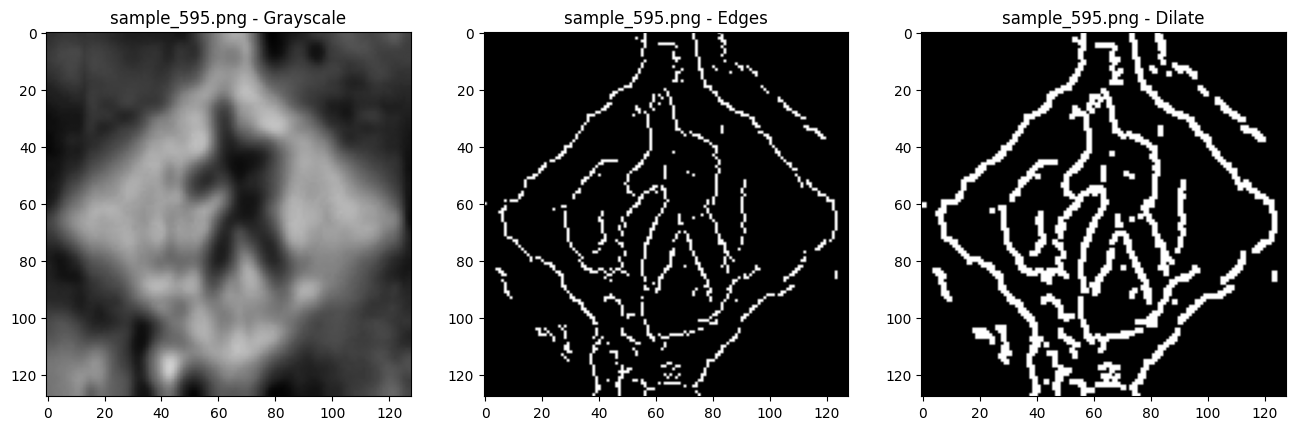

In [159]:
# ------------------------------------------------------
# TEST: Morphological operations
# ------------------------------------------------------
'''
Morphological operations applied to Canny edge outputs resulted in poorer structural feature qualities due to:
- Too many broken edges caused by low-res edge detection
'''

kernel = np.ones((2,2), np.uint8)

dilate = cv.dilate(edges, kernel, iterations=1)

fig, ax = plt.subplots(1,3, figsize=(16,8))

# CLAHE
ax[0].set_title(f"sample_{img_num:03}.png - Grayscale")
ax[0].imshow(img_hsv2gray_clahe, cmap='gray', vmin=0, vmax=255)

# Edge
ax[1].set_title(f"sample_{img_num:03}.png - Edges")
ax[1].imshow(edges, cmap='gray', vmin=0, vmax=255)

# Dilate
ax[2].set_title(f"sample_{img_num:03}.png - Dilate")
ax[2].imshow(dilate, cmap='gray', vmin=0, vmax=255)

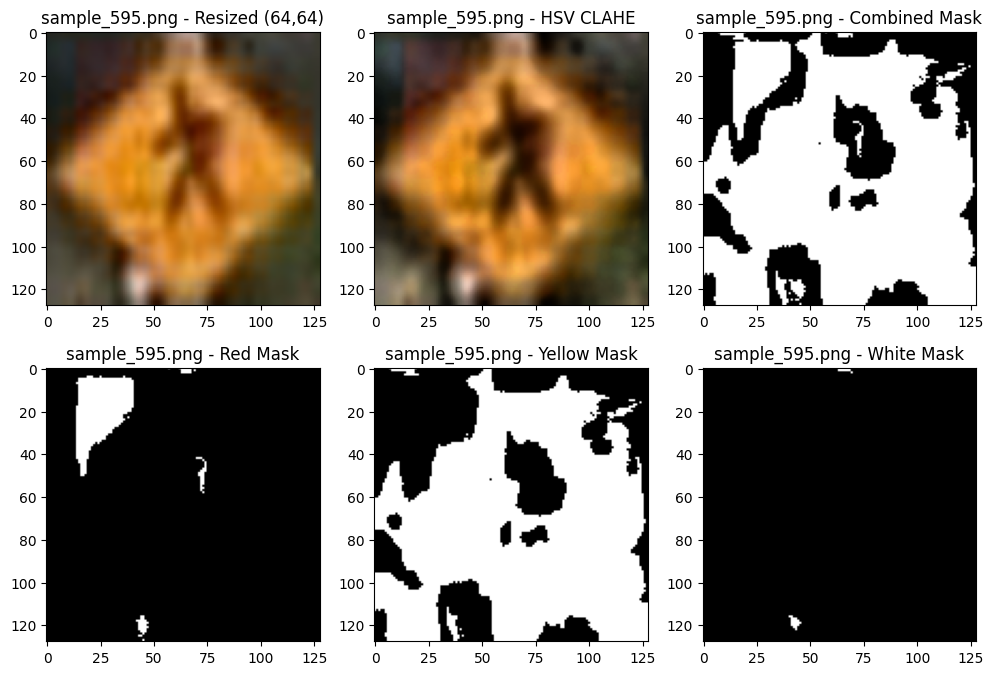

In [160]:
# ------------------------------------------------------
# TEST: Color masking
# ------------------------------------------------------
'''
Color masking not effective due to:
- Low image resolution
- Different lighting / image quality causes inconsistent sign colors. As a result, color ranges are not able to capture full definition of red/yellow/white
'''

img_hsv = cv.cvtColor(img_hsv_clahe, cv.COLOR_RGB2HSV)

lower_red1 = np.array([0,50,50])
upper_red1 = np.array([10,255,255])

lower_red2 = np.array([160,50,50])
upper_red2 = np.array([180,255,255])

mask_red = cv.inRange(img_hsv, lower_red1, upper_red1) | cv.inRange(img_hsv, lower_red2, upper_red2)

lower_yellow = np.array([15,50,50])
upper_yellow = np.array([40,255,255])

mask_yellow = cv.inRange(img_hsv, lower_yellow, upper_yellow)

lower_white = np.array([0,0,180])
upper_white = np.array([180,60,255])

mask_white = cv.inRange(img_hsv, lower_white, upper_white)

mask_combined = mask_red | mask_yellow | mask_white

fig, ax = plt.subplots(2,3, figsize=(12,8))

# Original image (img)
ax[0][0].set_title(f"sample_{img_num:03}.png - Resized (64,64)")
ax[0][0].imshow(img)

# HSV CLAHE
ax[0][1].set_title(f"sample_{img_num:03}.png - HSV CLAHE")
ax[0][1].imshow(img_hsv_clahe)

# Combined mask
ax[0][2].set_title(f"sample_{img_num:03}.png - Combined Mask")
ax[0][2].imshow(mask_combined, cmap='gray', vmin=0, vmax=255)

# Red mask
ax[1][0].set_title(f"sample_{img_num:03}.png - Red Mask")
ax[1][0].imshow(mask_red, cmap='gray', vmin=0, vmax=255)

# Yellow mask
ax[1][1].set_title(f"sample_{img_num:03}.png - Yellow Mask")
ax[1][1].imshow(mask_yellow, cmap='gray', vmin=0, vmax=255)

# White mask
ax[1][2].set_title(f"sample_{img_num:03}.png - White Mask")
ax[1][2].imshow(mask_white, cmap='gray', vmin=0, vmax=255)



circle/other
circle/other
circle/other


Text(0.5, 1.0, 'Contours + Shape')

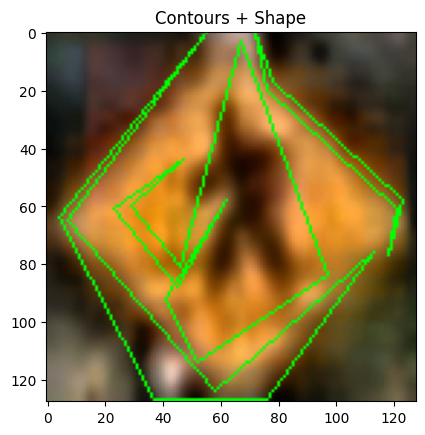

In [161]:
# ------------------------------------------------------
# TEST: Contours and polygon approximation
# ------------------------------------------------------
edges_test = edges.copy()
edges_test = cv.GaussianBlur(edges_test, (3,3), 0)

contours, hierarchy = cv.findContours(edges_test, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

contour_img = img_hsv_clahe.copy()

for cnt in contours:
  if cv.contourArea(cnt) < 100:
    continue

  epsilon = 0.02 * cv.arcLength(cnt, True)
  approx = cv.approxPolyDP(cnt,epsilon, True)
  num_vertices = len(approx)

  if num_vertices == 3:
    shape = "triangle"        # Yield signs
  elif num_vertices == 4:
    shape = "rectangle"       # Speed signs
  elif num_vertices == 5:
    shape = "pentagon"
  elif num_vertices == 8:
    shape = "octagon"         # Stop signs
  else:
    shape = "circle/other"

  print(shape)

  # Draw polygon
  cv.drawContours(contour_img, [approx], -1, (0,255,0), 1)

plt.imshow(contour_img)
plt.title("Contours + Shape")

In [162]:
test = prep.preprocess(img)
print(test.shape)


(128, 128, 4)
